# Task 5 — Penalty Strength Experiment (lambda sweep)

**Goal:** investigate how the penalty strength \(\lambda\) affects whether QAOA returns portfolios with exactly \(K=3\) selected stocks.

The challenge asks you to sweep \(\lambda\), plot the fraction of samples that select exactly K stocks, assess how low the penalty can be before invalid solutions are favored, and examine how often QAOA returns the single best portfolio.

This notebook uses a local statevector simulation, samples 4096 shots per setting, and runs a small number of optimizer restarts. Increase the restart count or iteration budget if runtime permits.

## 1. Imports and fixed challenge data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from scipy.optimize import minimize
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector

rng = np.random.default_rng(2026)
n, K, q = 6, 3, 0.5
mu = rng.uniform(0.05, 0.25, n)
A = rng.normal(0, 0.1, (n, n))
sigma = A @ A.T

def portfolio_cost(x, lam):
    x = np.asarray(x, dtype=int)
    return float(q * (x @ sigma @ x) - mu @ x + lam * (x.sum() - K) ** 2)

print("Stocks:", n, "| required selections K:", K)

Stocks: 6 | required selections K: 3


## 2. Build the Hamiltonian for any lambda

In [2]:
def build_cost_hamiltonian(lam):
    a = q * np.diag(sigma) - mu + lam * (1 - 2 * K)
    b = {(i, j): 2 * q * sigma[i, j] + 2 * lam
         for i in range(n) for j in range(i + 1, n)}
    terms = {}
    def add(label, coeff):
        terms[label] = terms.get(label, 0.0) + float(coeff)

    identity = "I" * n
    add(identity, lam * K**2)
    for i in range(n):
        label = ["I"] * n
        label[n - 1 - i] = "Z"
        add(identity, a[i] / 2)
        add("".join(label), -a[i] / 2)
    for (i, j), coeff in b.items():
        add(identity, coeff / 4)
        li = ["I"] * n
        li[n - 1 - i] = "Z"
        add("".join(li), -coeff / 4)
        lj = ["I"] * n
        lj[n - 1 - j] = "Z"
        add("".join(lj), -coeff / 4)
        lij = ["I"] * n
        lij[n - 1 - i] = "Z"
        lij[n - 1 - j] = "Z"
        add("".join(lij), coeff / 4)

    return SparsePauliOp.from_list(
        [(label, coeff) for label, coeff in terms.items() if abs(coeff) > 1e-12]
    ).simplify()

def qaoa_state(params, p, operator, coeff_map):
    gammas, betas = params[:p], params[p:]
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for layer in range(p):
        gamma, beta = gammas[layer], betas[layer]
        for label, coeff in coeff_map.items():
            z_positions = [pos for pos, char in enumerate(label) if char == "Z"]
            if len(z_positions) == 1:
                qc.rz(2 * gamma * coeff, n - 1 - z_positions[0])
            elif len(z_positions) == 2:
                qa, qb = n - 1 - z_positions[0], n - 1 - z_positions[1]
                qc.rzz(2 * gamma * coeff, qa, qb)
        for qubit in range(n):
            qc.rx(2 * beta, qubit)
    return Statevector.from_instruction(qc)

def get_coeff_map(operator):
    return {label: float(np.real(coeff))
            for label, coeff in zip(operator.paulis.to_labels(), operator.coeffs)}

def exact_cost_range(lam):
    costs = [portfolio_cost(np.array(bits), lam)
             for bits in product([0, 1], repeat=n)]
    return float(min(costs)), float(max(costs))

def exact_best_valid(lam):
    rows = []
    for bits in product([0, 1], repeat=n):
        x = np.array(bits, dtype=int)
        if x.sum() == K:
            rows.append((portfolio_cost(x, lam), "".join(map(str, bits))))
    return min(rows)

print("Hamiltonian and experiment helpers ready.")

Hamiltonian and experiment helpers ready.


## 3. Sweep lambda and sample QAOA outputs

We use depth p=2 for this initial sweep and optimize each lambda separately. For each lambda, we compute the valid-sample fraction and the frequency of the exact best valid portfolio.

**Important:** the approximation ratio and the objective's minimum/maximum depend on lambda. Here the main metrics are feasibility rate and best-valid-portfolio frequency.

In [3]:
lambda_values = [0.05, 0.1, 0.25, 0.5, 1.0, 2.0, 5.0]
p = 2
restarts = 2
maxiter = 140
shots = 4096

rng_opt = np.random.default_rng(2505)
rng_sample = np.random.default_rng(9876)
sweep_results = []

for lam in lambda_values:
    operator = build_cost_hamiltonian(lam)
    coeff_map = get_coeff_map(operator)
    best_result = None

    for restart in range(restarts):
        x0 = np.concatenate([
            rng_opt.uniform(0, np.pi, p),
            rng_opt.uniform(0, np.pi / 2, p),
        ])
        result = minimize(
            fun=lambda params, op=operator, cm=coeff_map, depth=p:
                float(np.real(qaoa_state(params, depth, op, cm).expectation_value(op))),
            x0=x0,
            method="COBYLA",
            options={"maxiter": maxiter, "rhobeg": 0.5},
        )
        if best_result is None or result.fun < best_result.fun:
            best_result = result

    state = qaoa_state(best_result.x, p, operator, coeff_map)
    probabilities = state.probabilities()
    indices = rng_sample.choice(2**n, size=shots, p=probabilities)

    sample_counts = {}
    for index in indices:
        # Qiskit index bit i corresponds to qubit i; convert to stock order.
        bits = format(index, f"0{n}b")[::-1]
        sample_counts[bits] = sample_counts.get(bits, 0) + 1

    valid_count = sum(count for bits, count in sample_counts.items()
                      if sum(int(bit) for bit in bits) == K)
    best_valid_cost, best_valid_bits = exact_best_valid(lam)
    best_valid_count = sample_counts.get(best_valid_bits, 0)
    c_min, c_max = exact_cost_range(lam)
    expected = float(np.real(state.expectation_value(operator)))
    ratio = (c_max - expected) / (c_max - c_min) if c_max > c_min else np.nan

    row = {
        "lambda": lam,
        "expected_cost": expected,
        "approximation_ratio": ratio,
        "valid_fraction": valid_count / shots,
        "best_valid_bits": best_valid_bits,
        "best_valid_cost": best_valid_cost,
        "best_valid_fraction": best_valid_count / shots,
        "optimizer_evaluations": int(best_result.nfev),
    }
    sweep_results.append(row)
    print(
        f'lambda={lam:>4} | valid fraction={row["valid_fraction"]:.3f} | '
        f'best valid {best_valid_bits} frequency={row["best_valid_fraction"]:.3f} | '
        f'<C>={expected:.5f} | ratio={ratio:.4f}'
    )

lambda=0.05 | valid fraction=0.204 | best valid 011001 frequency=0.023 | <C>=-0.44971 | ratio=0.8884
lambda= 0.1 | valid fraction=0.519 | best valid 011001 frequency=0.034 | <C>=-0.38493 | ratio=0.9096
lambda=0.25 | valid fraction=0.662 | best valid 011001 frequency=0.037 | <C>=-0.30417 | ratio=0.9278
lambda= 0.5 | valid fraction=0.876 | best valid 011001 frequency=0.043 | <C>=-0.31170 | ratio=0.9618
lambda= 1.0 | valid fraction=0.971 | best valid 011001 frequency=0.046 | <C>=-0.30481 | ratio=0.9791
lambda= 2.0 | valid fraction=0.781 | best valid 011001 frequency=0.050 | <C>=0.35855 | ratio=0.9534
lambda= 5.0 | valid fraction=0.688 | best valid 011001 frequency=0.037 | <C>=1.47020 | ratio=0.9566


## 4. Plot fraction of samples selecting exactly K stocks

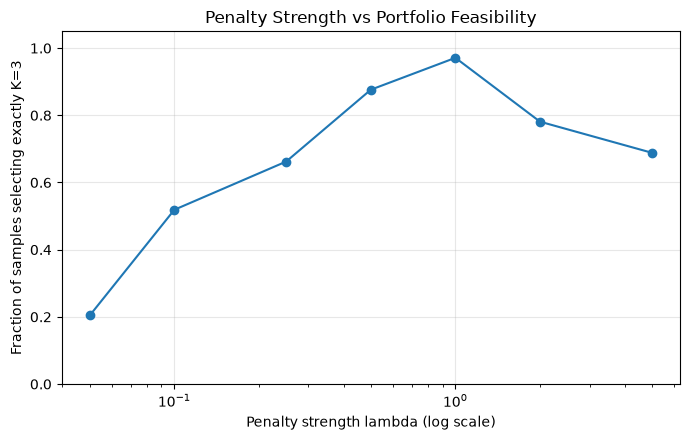

In [4]:
plt.figure(figsize=(7, 4.5))
plt.plot(
    [row["lambda"] for row in sweep_results],
    [row["valid_fraction"] for row in sweep_results],
    marker="o",
)
plt.xscale("log")
plt.ylim(0, 1.05)
plt.xlabel("Penalty strength lambda (log scale)")
plt.ylabel("Fraction of samples selecting exactly K=3")
plt.title("Penalty Strength vs Portfolio Feasibility")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Plot frequency of the exact best valid portfolio

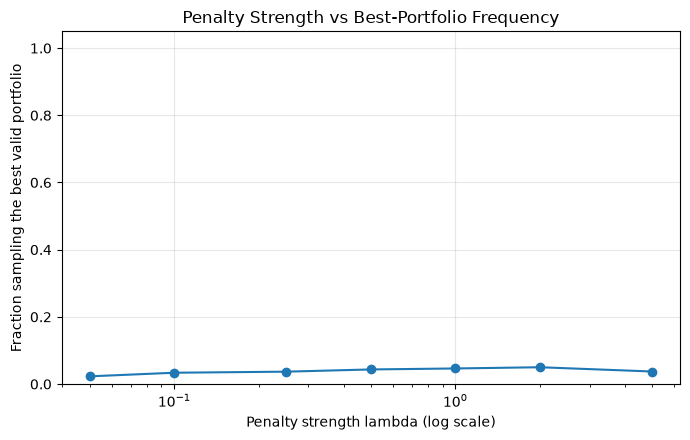

In [5]:
plt.figure(figsize=(7, 4.5))
plt.plot(
    [row["lambda"] for row in sweep_results],
    [row["best_valid_fraction"] for row in sweep_results],
    marker="o",
)
plt.xscale("log")
plt.ylim(0, 1.05)
plt.xlabel("Penalty strength lambda (log scale)")
plt.ylabel("Fraction sampling the best valid portfolio")
plt.title("Penalty Strength vs Best-Portfolio Frequency")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 6. Interpret and record your results

Use your actual printed values and plots to answer:

1. At which tested lambda does the valid-sample fraction become acceptably high?
2. What is the smallest tested lambda where valid portfolios are not overwhelmed by invalid selections?
3. How often did the exact best valid bitstring appear in the 4096 samples?
4. Does increasing lambda always improve the valid-sample fraction? If not, discuss the optimizer's finite restarts and non-convex objective.

Do not claim a universal threshold from this finite sweep. The threshold is specific to this synthetic dataset, QAOA depth, optimizer settings, and random starts.

## Task 5 completion checklist

- [ ] Notebook runs from top to bottom.
- [ ] It prints one row for every tested lambda.
- [ ] It displays both plots.
- [ ] You record the observed feasibility rate and best-valid-portfolio frequency.

After Task 5, the computational experiments are complete. The remaining work is to organize results, create a clear README, and prepare the required slide PDF. Keep the numerical claims grounded in the outputs from your own run.